# Hematopoietic dataset (two batches)

Loads `/gpfs01/berens/user/sdamrich/data/ne_aligned/hematopoietic`, which holds two
sorted-population batches of mouse hematopoietic progenitors as gzipped tab-separated
count matrices (**genes as rows, cells as columns**) plus one cell-type table per batch.

The two batches do not share a cell-type vocabulary, so two variants are produced:

| variant | `res_path` | cell types |
| --- | --- | --- |
| all types | `.../hematopoietic` | all types present in either batch |
| shared types | `.../hematopoietic_shared` | only types present in **both** batches |

Each variant is preprocessed like the other `load_*` notebooks (Seurat-style filtering,
`seurat_v3` HVG selection of 1000 genes, library-size normalisation + `log1p`) and saved
as `X1.npy` / `X2.npy` / `X1_counts.npy` / `X2_counts.npy` / `labels*.npy` / ... so that the
`compute_aligned_*` scripts can pick it up with a plain `dataset` string.

In [1]:
%load_ext autoreload
%autoreload 2

import os

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc

from ne_aligned_utils.plot import plot_variant
from ne_aligned_utils.preprocessing import check_saved, describe_batches, prepare

In [2]:
base_path = "/gpfs01/berens/user/sdamrich/data/ne_aligned"

data_path = os.path.join(base_path, "hematopoietic")               # raw .txt.gz files live here
res_path_all = data_path                                           # variant with all cell types
res_path_shared = os.path.join(base_path, "hematopoietic_shared")  # variant with shared types only
fig_path = os.path.join(base_path, "figures")

os.makedirs(res_path_shared, exist_ok=True)

sorted(os.listdir(data_path))

['X1.npy',
 'X1_counts.npy',
 'X2.npy',
 'X2_counts.npy',
 'b1_celltype.txt.gz',
 'b1_exprs.txt.gz',
 'b2_celltype.txt.gz',
 'b2_exprs.txt.gz',
 'cell_type_names.npy',
 'cells_metadata.csv',
 'combined_1000genes.h5ad',
 'dataset_names.npy',
 'features.txt',
 'labels1.npy',
 'labels2.npy']

## Raw loading

The expression files are genes x cells, so they get transposed on the way into `AnnData`.
The cell-type table is reindexed onto the expression columns instead of trusting the row
order.

In [3]:
def read_batch(prefix, method):
    """Read one batch (`b1`/`b2`) into an AnnData with cells as observations."""
    exprs = pd.read_csv(
        os.path.join(data_path, f"{prefix}_exprs.txt.gz"),
        sep="\t",
        index_col=0,
    )  # genes x cells
    ctype = pd.read_csv(
        os.path.join(data_path, f"{prefix}_celltype.txt.gz"),
        sep="\t",
        index_col="CellId",
    )

    # align the cell-type table to the columns of the count matrix
    ctype = ctype.reindex(exprs.columns)
    assert not ctype["CellType"].isna().any(), f"{prefix}: cells without a cell type"

    adata = ad.AnnData(
        X=exprs.to_numpy(dtype=np.float32).T,  # cells x genes
        obs=pd.DataFrame(index=exprs.columns.astype(str)),
        var=pd.DataFrame(index=exprs.index.astype(str)),
    )
    adata.obs["batch"] = prefix
    adata.obs["method"] = method
    adata.obs["cell_type"] = pd.Categorical(ctype["CellType"].astype(str).to_numpy())
    adata.layers["counts"] = adata.X.copy()
    return adata


assert os.path.basename(data_path) == "hematopoietic", (
    f"data_path points at {data_path!r} -- re-run the paths cell above (the load_* "
    "notebooks share one kernel, so a sibling notebook may have overwritten it)"
)

adata_b1 = read_batch("b1", "data1")
adata_b2 = read_batch("b2", "data2")

adata_b1.shape, adata_b2.shape

((2729, 3467), (1920, 3467))

## Minimal inspection of the raw batches

In [4]:
# the batches are still separate here, and each carries its own obs["batch"]
raw_is_integer = all([describe_batches(adata_b1), describe_batches(adata_b2)])
print("raw counts everywhere:", raw_is_integer)

for name, adata in [("b1", adata_b1), ("b2", adata_b2)]:
    print(f"\n{name} cell types:")
    print(adata.obs["cell_type"].value_counts().to_string())

--- b1 (2729 cells x 3467 genes) ---
integer counts: True | min: 0.0
zero fraction: 0.892
genes/cell   min 76, median 366, max 1072
counts/cell  min 88, median 809, max 4815

--- b2 (1920 cells x 3467 genes) ---
integer counts: True | min: 0.0
zero fraction: 0.421
genes/cell   min 1076, median 2007, max 2880
counts/cell  min 3172, median 264490, max 8355896

raw counts everywhere: True

b1 cell types:
cell_type
GMP    1154
MEP    1095
CMP     480

b2 cell types:
cell_type
MPP         368
MEP         362
CMP         328
LTHSC       323
LMPP        280
Unsorted    136
GMP         123


In [5]:
# the two batches should already be on the same gene set, with disjoint cell ids
print("gene sets identical:", adata_b1.var_names.equals(adata_b2.var_names))
print("shared cell ids:", len(adata_b1.obs_names.intersection(adata_b2.obs_names)))

types_b1 = set(adata_b1.obs["cell_type"].unique())
types_b2 = set(adata_b2.obs["cell_type"].unique())
shared_types = sorted(types_b1 & types_b2)

print("b1 only:", sorted(types_b1 - types_b2))
print("b2 only:", sorted(types_b2 - types_b1))
print("shared :", shared_types)

gene sets identical: True
shared cell ids: 0
b1 only: []
b2 only: ['LMPP', 'LTHSC', 'MPP', 'Unsorted']
shared : ['CMP', 'GMP', 'MEP']


In [6]:
# per-batch counts of every cell type, for a quick look at what the batches share
pd.crosstab(
    pd.concat([adata_b1.obs["cell_type"], adata_b2.obs["cell_type"]]),
    pd.concat([adata_b1.obs["batch"], adata_b2.obs["batch"]]),
)

batch,b1,b2
cell_type,,
CMP,480,328
GMP,1154,123
LMPP,0,280
LTHSC,0,323
MEP,1095,362
MPP,0,368
Unsorted,0,136


## Combine the batches

In [7]:
adata_comb = sc.concat(
    {"b1": adata_b1, "b2": adata_b2},
    axis=0,
    join="inner",
    label="batch_concat",
    index_unique=None,
)
adata_comb.obs["method"] = adata_comb.obs["method"].astype("category")
adata_comb.obs["batch"] = adata_comb.obs["batch"].astype("category")
adata_comb.obs["cell_type"] = adata_comb.obs["cell_type"].astype("category")

if "counts" not in adata_comb.layers:
    adata_comb.layers["counts"] = adata_comb.X.copy()

adata_comb

AnnData object with n_obs × n_vars = 4649 × 3467
    obs: 'batch', 'method', 'cell_type', 'batch_concat'
    layers: 'counts'

## Preprocessing + saving

`prepare` lives in [preprocessing.py](../src/ne_aligned_utils/preprocessing.py) and is
shared with the other `load_*` notebooks. It mirrors the Seurat pipeline:
`CreateSeuratObject(min.cells=3, min.features=10)`, `SelectIntegrationFeatures(nfeatures=1000)`
(via `seurat_v3` HVG on raw counts, so integer counts are used), then
`NormalizeData(LogNormalize, scale.factor=1e4)`.

A few things worth being explicit about:

- **The 1000 genes are shared by both batches**, not selected per batch. `batch_key="method"`
  makes the selection batch-*aware*: scanpy ranks genes within each batch, then picks the
  top 1000 by median rank across batches into a single `var["highly_variable"]` mask. Both
  batches are then re-indexed to the same `features` list, so `X1` and `X2` have identical
  columns in identical order.
- **HVG selection is per variant.** Cells are subset to `keep_types` *before* `filter_genes`
  and before the HVG call, so the shared-type variant selects genes that are variable among
  `{CMP, GMP, MEP}` specifically. The two variants therefore end up with different gene sets.
- **Raw counts are saved too**, restricted to the selected genes and cells and in the same
  column order as `X1`/`X2` (`X1_counts.npy` / `X2_counts.npy`).
- **A 50D PCA is saved too** (`X1_pca50.npy` / `X2_pca50.npy`), fitted on `X1` stacked on
  `X2` and then split by batch. That is one PCA over both batches rather than one per batch,
  so the two blocks share a coordinate system.
- Labels are encoded over the *combined* cells of a variant, so a given integer means the
  same cell type in both batches.

In [15]:
all_types = sorted(set(adata_comb.obs["cell_type"].unique()))

out_all = prepare(adata_comb, res_path_all, "hematopoietic", keep_types=all_types)

[hematopoietic] filters dropped 0 cells and 0 genes
[hematopoietic] joint PCA (2729, 50) + (1920, 50) -> X1_pca50.npy, X2_pca50.npy
[hematopoietic] saved to /gpfs01/berens/user/sdamrich/data/ne_aligned/hematopoietic


In [16]:
out_shared = prepare(
    adata_comb, res_path_shared, "hematopoietic_shared", keep_types=shared_types
)

[hematopoietic_shared] filters dropped 0 cells and 0 genes
[hematopoietic_shared] joint PCA (2729, 50) + (813, 50) -> X1_pca50.npy, X2_pca50.npy
[hematopoietic_shared] saved to /gpfs01/berens/user/sdamrich/data/ne_aligned/hematopoietic_shared


## Inspection of the two variants

In [10]:
for out in [out_all, out_shared]:
    check_saved(out, counts_are_integer=raw_is_integer)
    print()

--- hematopoietic ---
X1: (2729, 1000)   X2: (1920, 1000)
7 cell types: ['CMP', 'GMP', 'LMPP', 'LTHSC', 'MEP', 'MPP', 'Unsorted']
            b1   b2
CMP        480  328
GMP       1154  123
LMPP         0  280
LTHSC        0  323
MEP       1095  362
MPP          0  368
Unsorted     0  136
log-normalised range: 0.000 .. 8.265
counts files: shapes match, same sparsity pattern as X1/X2, integer: True
raw count range: 0 .. 233308
joint PCA: (4649, 50) (rows are X1 stacked on X2)

--- hematopoietic_shared ---
X1: (2729, 1000)   X2: (813, 1000)
3 cell types: ['CMP', 'GMP', 'MEP']
       b1   b2
CMP   480  328
GMP  1154  123
MEP  1095  362
log-normalised range: 0.000 .. 8.265
counts files: shapes match, same sparsity pattern as X1/X2, integer: True
raw count range: 0 .. 208540
joint PCA: (3542, 50) (rows are X1 stacked on X2)



In [11]:
# HVGs are selected per variant, so the two variants have different gene sets
n_shared_feats = len(set(out_all["features"]) & set(out_shared["features"]))
print(f"HVGs in common between the two variants: {n_shared_feats} / {len(out_all['features'])}")

HVGs in common between the two variants: 774 / 1000


## PCA and t-SNE per variant

Same three-panel layout as the other `load_*` notebooks: each batch on its own, plus the
naive joint embedding, coloured by batch and by cell type. Before alignment the joint
embedding is expected to split by batch.

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Finding 90 nearest neighbors using Annoy approximate search using euclidean distance...
   --> Time elapsed: 0.87 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 0.08 seconds
===> Calculating PCA-based initialization...
   --> Time elapsed: 0.00 seconds
===> Running optimization with exaggeration=12.00, lr=227.42 for 250 iterations...
Iteration   50, KL divergence 3.3925, 50 iterations in 3.1241 sec
Iteration  100, KL divergence 3.4637, 50 iterations in 2.5792 sec
Iteration  150, KL divergence 3.4648, 50 iterations in 2.5457 sec
Iteration  200, KL divergence 3.4651, 50 iterations in 4.0766 sec
Iteration  250, KL divergence 3.4653, 50 iterations in 5.1352 sec
   --> Time elapsed: 17.46 seconds
===> Running optimization with exaggeration=1.00, lr=272

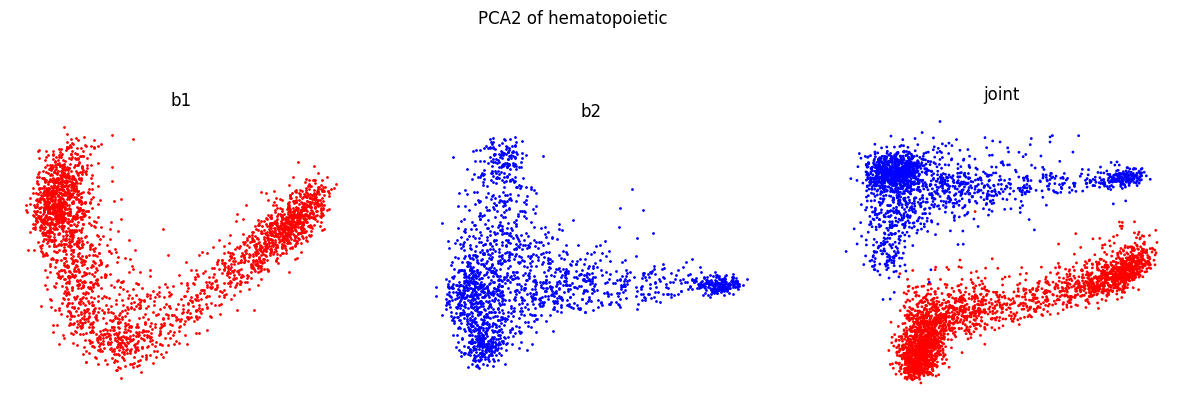

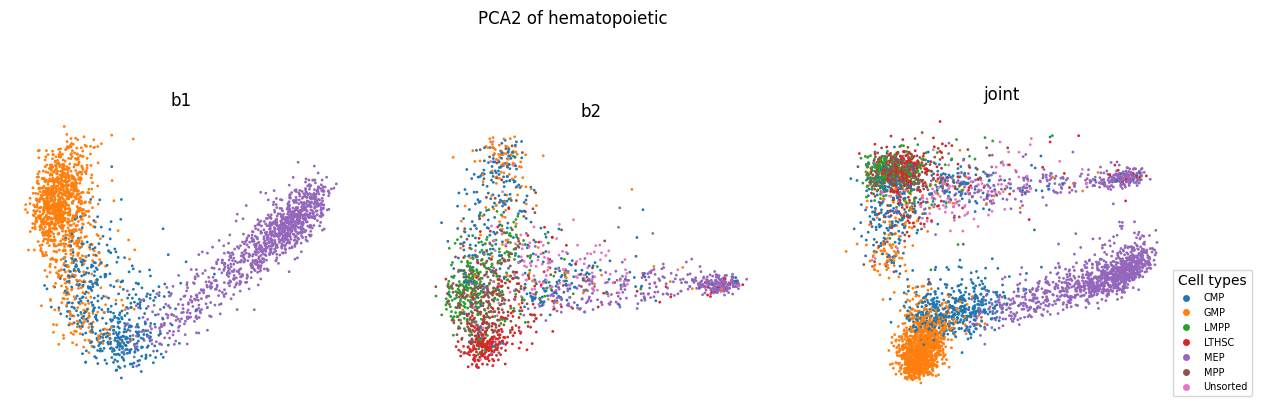

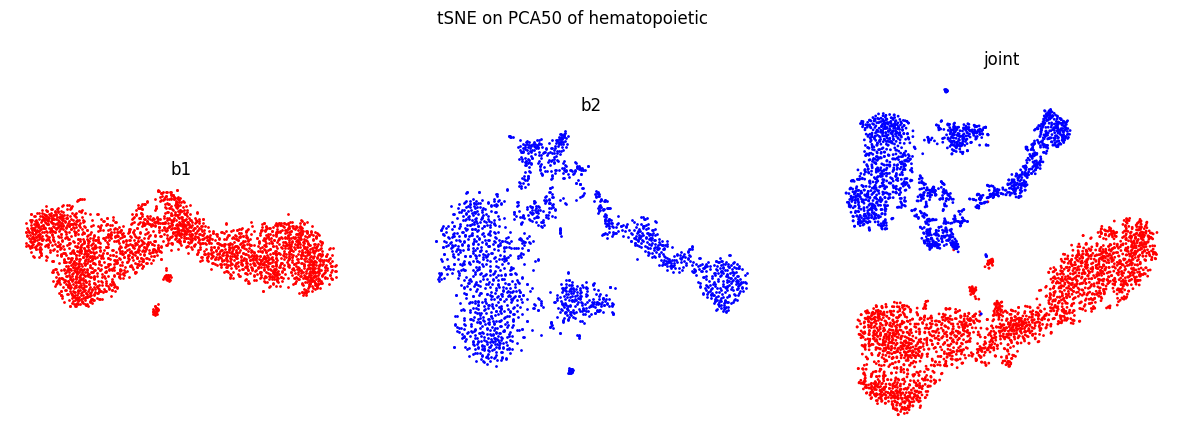

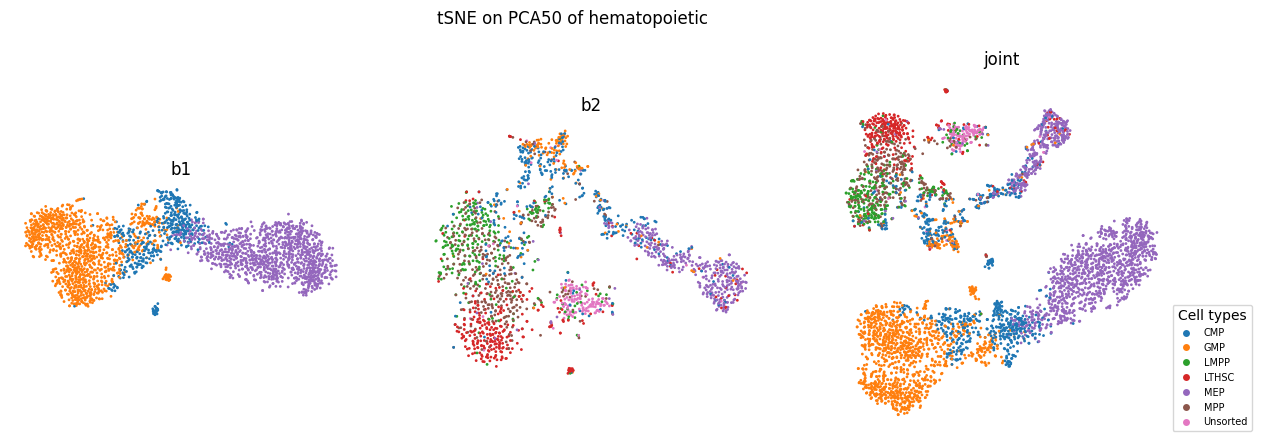

In [12]:
plot_variant(out_all, fig_dir=fig_path);

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Finding 90 nearest neighbors using Annoy approximate search using euclidean distance...
   --> Time elapsed: 0.87 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 0.07 seconds
===> Calculating PCA-based initialization...
   --> Time elapsed: 0.00 seconds
===> Running optimization with exaggeration=12.00, lr=227.42 for 250 iterations...
Iteration   50, KL divergence 3.3970, 50 iterations in 3.0887 sec
Iteration  100, KL divergence 3.4733, 50 iterations in 2.4923 sec
Iteration  150, KL divergence 3.4740, 50 iterations in 2.4376 sec
Iteration  200, KL divergence 3.4739, 50 iterations in 2.4367 sec
Iteration  250, KL divergence 3.4739, 50 iterations in 2.4761 sec
   --> Time elapsed: 12.93 seconds
===> Running optimization with exaggeration=1.00, lr=272

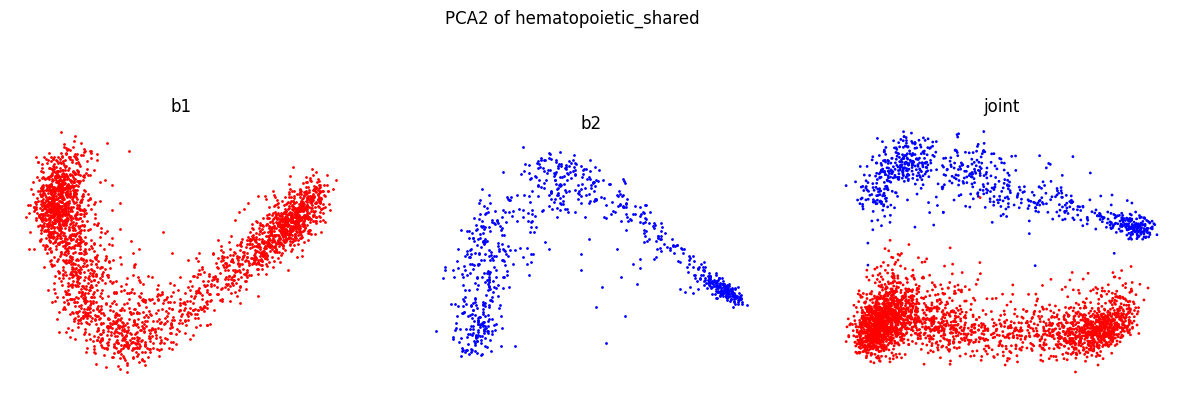

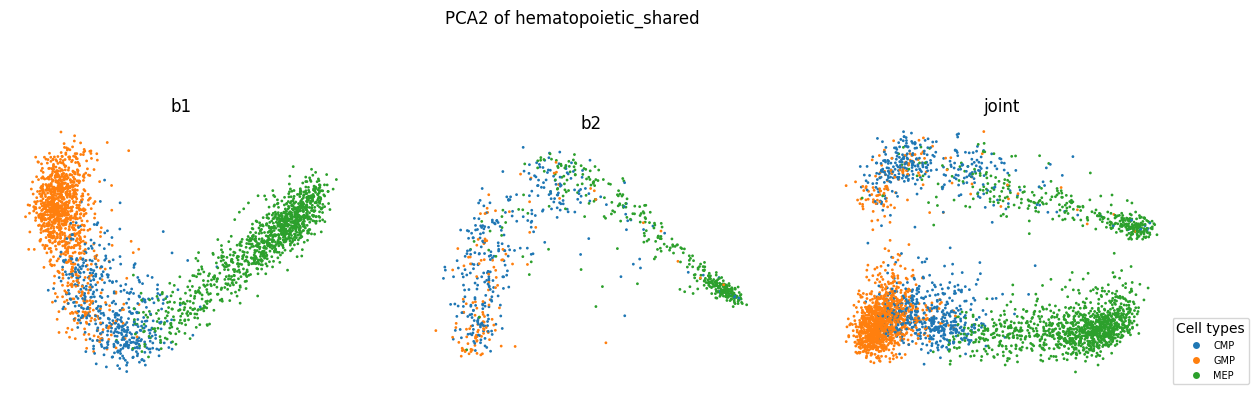

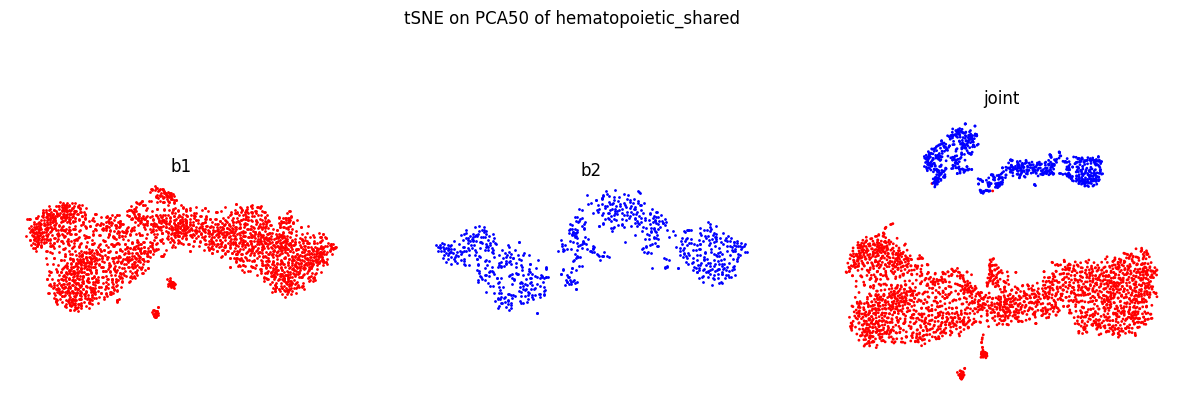

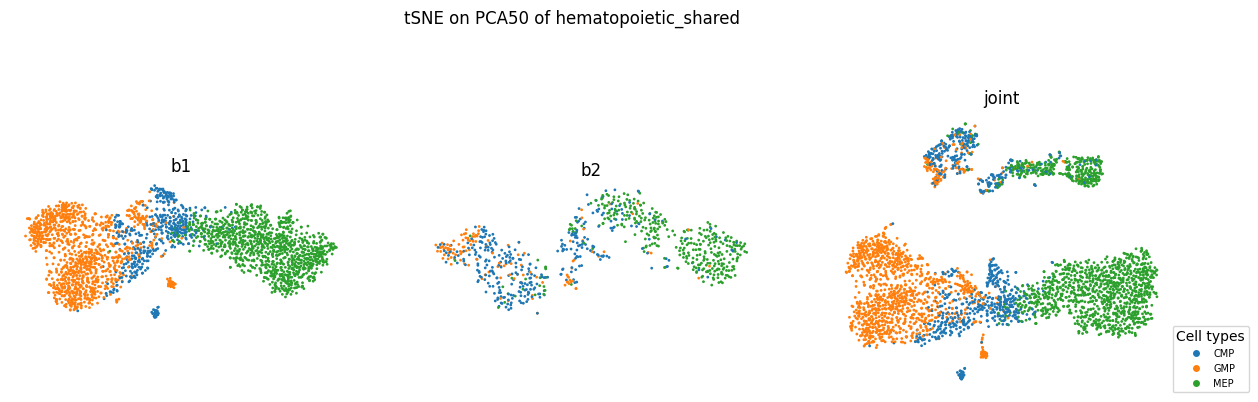

In [13]:
plot_variant(out_shared, fig_dir=fig_path);

## Round trip

Check that the saved arrays read back the way the `compute_aligned_*` scripts expect
(`X1.npy` / `X2.npy` / `labels1.npy` / `labels2.npy` in `res_path`).

In [17]:
for res_path in [res_path_all, res_path_shared]:
    print(f"--- {os.path.basename(res_path)} ---")
    print(sorted(f for f in os.listdir(res_path) if not f.endswith(".txt.gz")))
    X1 = np.load(os.path.join(res_path, "X1.npy"))
    X2 = np.load(os.path.join(res_path, "X2.npy"))
    C1 = np.load(os.path.join(res_path, "X1_counts.npy"))
    C2 = np.load(os.path.join(res_path, "X2_counts.npy"))
    y1 = np.load(os.path.join(res_path, "labels1.npy"))
    y2 = np.load(os.path.join(res_path, "labels2.npy"))
    names = np.load(os.path.join(res_path, "cell_type_names.npy"), allow_pickle=True)
    features = pd.read_csv(os.path.join(res_path, "features.txt"))["gene"].to_list()
    P1 = np.load(os.path.join(res_path, "X1_pca50.npy"))
    P2 = np.load(os.path.join(res_path, "X2_pca50.npy"))
    assert (P1.shape[0], P2.shape[0]) == (X1.shape[0], X2.shape[0]), "PCA misses cells"
    print("X:", X1.shape, X2.shape, " counts:", C1.shape, C2.shape)
    print("labels:", y1.shape, y2.shape, " features:", len(features), " types:", list(names))
    print("PCA:", P1.shape, P2.shape)
    print()

--- hematopoietic ---
['X1.npy', 'X1_counts.npy', 'X1_pca50.npy', 'X2.npy', 'X2_counts.npy', 'X2_pca50.npy', 'cell_type_names.npy', 'cells_metadata.csv', 'combined_1000genes.h5ad', 'dataset_names.npy', 'features.txt', 'labels1.npy', 'labels2.npy', 'pca50_joint.npy']
X: (2729, 1000) (1920, 1000)  counts: (2729, 1000) (1920, 1000)
labels: (2729,) (1920,)  features: 1000  types: ['CMP', 'GMP', 'LMPP', 'LTHSC', 'MEP', 'MPP', 'Unsorted']
PCA: (2729, 50) (1920, 50)

--- hematopoietic_shared ---
['X1.npy', 'X1_counts.npy', 'X1_pca50.npy', 'X2.npy', 'X2_counts.npy', 'X2_pca50.npy', 'cell_type_names.npy', 'cells_metadata.csv', 'combined_1000genes.h5ad', 'dataset_names.npy', 'features.txt', 'labels1.npy', 'labels2.npy', 'pca50_joint.npy']
X: (2729, 1000) (813, 1000)  counts: (2729, 1000) (813, 1000)
labels: (2729,) (813,)  features: 1000  types: ['CMP', 'GMP', 'MEP']
PCA: (2729, 50) (813, 50)

